# Regresión logística por actividad productiva (municipios rurales) — validación agrupada por municipio y por departamento

> **Copia de `regresion_logistica.ipynb` con dos agrupaciones.** Mismos datos, mismas variables (con el mismo VIF
> iterativo), misma variable objetivo (tasa de deforestación > 0) y misma partición temporal (entrenamiento
> 2021–2024, prueba 2025). Lo único que cambia es **cómo se agrupan las filas**, y aquí se corren las dos versiones
> lado a lado:
>
> - **Agrupación por municipio** (la del notebook original): en la validación cruzada un municipio nunca está a la
>   vez en ajuste y validación, y los errores estándar se agrupan por municipio.
> - **Agrupación por departamento** (la del gradient boosting del equipo, `modelos y clusters/gradient_boosting.ipynb`):
>   todos los municipios de un departamento quedan en el mismo pliegue, y los errores estándar se agrupan por
>   departamento. Es más exigente, porque los municipios vecinos se parecen y sus errores pueden estar correlacionados.
>
> Cada agrupación hace su propia búsqueda de hiperparámetros y produce su propio modelo final. Además, se agrega una
> evaluación sobre todo 2021–2025 dejando fuera municipios o departamentos completos (paso 12), equivalente a la
> sección 6 del gradient boosting. El notebook original `regresion_logistica.ipynb` no se modifica.

**Pregunta.** ¿El crédito de cada cadena (FINAGRO), el área cosechada de cada cultivo (EVA) y la ganadería (ICA)
de un municipio en un año ayudan a anticipar si **tendrá alguna deforestación** (tasa de deforestación del
IDEAM > 0) el año siguiente? ¿Cuál es la dirección y el tamaño de cada asociación, y siguen siendo significativas
cuando los errores se agrupan por departamento?

**Pasos** (se omite el análisis exploratorio):

1. Carga de datos
2. Variable objetivo
3. Variables explicativas por actividad (rezagadas un año)
4. Selección de la muestra
5. Partición temporal: entrenamiento 2021–2024 / prueba 2025, y grupos (municipio y departamento)
6. Preprocesamiento (imputación, estandarización, codificación)
7. Multicolinealidad: VIF iterativo y eliminación de variables
8. Hiperparámetros con `GridSearchCV`: una vez agrupando por municipio y otra por departamento
9. Modelos finales
10. Comparación de modelos en 2025: AUC
11. Comparación de modelos en 2025: matriz de confusión
12. Evaluación dejando territorios completos fuera (municipios o departamentos, 2021–2025)
13. Interpretación: *odds ratios*, errores robustos por municipio y por departamento, efectos marginales y pruebas por bloque
14. Comparación de especificaciones (estructural, principal, con persistencia)
15. Guardado
16. Conclusiones

## 1. Carga de datos

In [1]:
import os
import time
import warnings
from pathlib import Path

warnings.filterwarnings("ignore")
RAIZ = Path.cwd().resolve()
while not (RAIZ / "main_local.py").exists() and RAIZ != RAIZ.parent:
    RAIZ = RAIZ.parent
os.chdir(RAIZ)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm

pd.set_option("display.max_columns", 40, "display.width", 200)
SEMILLA = 42

panel = pd.read_parquet("datos/analisis/municipio_anio.parquet")
print(panel.shape)

(6738, 28)


## 2. Variable objetivo

`deforesta` = 1 si la **tasa de deforestación del IDEAM** (`def_ideam_ha / bosque_ideam_ha`) del municipio en el
año *t* es **mayor que 0**; 0 si es cero. Como todos los municipios de la muestra tienen bosque, equivale a
"perdió alguna superficie de bosque, aunque sea una fracción de hectárea". Es la misma regla del Random Forest
correspondiente.

In [2]:
REGLA_OBJETIVO = "tasa_def_ideam > 0"

panel = panel.sort_values(["cod_dane", "anio"]).reset_index(drop=True)
panel["deforesta"] = np.where(panel.tasa_def_ideam.isna(), np.nan, (panel.tasa_def_ideam > 0).astype(float))

## 3. Variables explicativas por actividad productiva

Son las 15 variables iniciales del Random Forest final. Crédito, cultivos y ganado son de *t − 1* y están en
log(1 + x). En la logística **el logaritmo sí importa**: el modelo supone que el logit cambia linealmente con cada
variable, y el log hace que esa linealidad sea razonable para montos y áreas muy asimétricos.

| # | Variable | Definición (en *t − 1*) | Fuente |
|---|---|---|---|
| 1–5 | `log_credito_ganaderia`, `_cafe`, `_arroz`, `_cacao`, `_palma` | Crédito del eslabón de producción de cada cadena (millones de pesos) | FINAGRO |
| 6 | `log_credito_otras_cadenas` | Crédito de producción de las demás cadenas | FINAGRO |
| 7–10 | `log_cosechada_cafe`, `_arroz`, `_palma`, `_cacao` | Hectáreas cosechadas de cada cultivo | EVA |
| 11 | `log_cosechada_otros` | Hectáreas cosechadas de los demás cultivos | EVA |
| 12 | `log_bovinos` | Inventario bovino | ICA |
| 13 | `log_bosque_inicial` | Bosque al inicio del panel (fija) | IDEAM |
| 14–15 | `region`, `ruralidad` | Atributos del municipio (categóricas) | Municipios |

También se construyen las variables del modelo logístico de totales (9 variables), solo para compararlo en el paso 10.

In [3]:
p = panel.copy()
CADENAS = {"ganaderia": "credito_ganaderia_produccion_mm", "cafe": "credito_cafe_produccion_mm",
           "arroz": "credito_arroz_produccion_mm", "cacao": "credito_cacao_produccion_mm",
           "palma": "credito_palma_produccion_mm"}
CULTIVOS = {"cafe": "cosechada_cafe_ha", "arroz": "cosechada_arroz_ha", "palma": "cosechada_palma_ha",
            "cacao": "cosechada_cacao_ha"}
p["credito_otras_cadenas_mm"] = (p.credito_produccion_mm - p[list(CADENAS.values())].sum(axis=1)).clip(lower=0)
p["cosechada_otros_ha"] = (p.area_cosechada_ha - p[list(CULTIVOS.values())].sum(axis=1, min_count=1)).clip(lower=0)

# Variables del modelo anterior de 9 variables (solo para comparar)
p["credito_otro_mm"] = (p.credito_mm - p.credito_produccion_mm).clip(lower=0)
cred_prod = p.credito_produccion_mm.replace(0, np.nan)
p["prop_cred_ganaderia_t"] = (p.credito_ganaderia_produccion_mm / cred_prod).fillna(0)
p["prop_cred_permanentes_t"] = (p[["credito_palma_produccion_mm", "credito_cacao_produccion_mm",
                                   "credito_cafe_produccion_mm"]].sum(axis=1) / cred_prod).fillna(0)

g = p.groupby("cod_dane", observed=True)
assert (g.anio.diff().dropna() == 1).all(), "hay anios faltantes dentro de algun municipio"
a_rezagar = {**{f"log_credito_{k}": v for k, v in CADENAS.items()},
             "log_credito_otras_cadenas": "credito_otras_cadenas_mm",
             **{f"log_cosechada_{k}": v for k, v in CULTIVOS.items()},
             "log_cosechada_otros": "cosechada_otros_ha",
             "log_bovinos": "bovinos", "log_def_l1": "def_ideam_ha",
             "log_credito_prod": "credito_produccion_mm", "log_credito_otro": "credito_otro_mm",
             "log_area_cosechada": "area_cosechada_ha"}
for nuevo, col in a_rezagar.items():
    p[nuevo] = np.log1p(g[col].shift(1))
p["prop_cred_ganaderia"] = g.prop_cred_ganaderia_t.shift(1)
p["prop_cred_permanentes"] = g.prop_cred_permanentes_t.shift(1)
p["log_bosque_inicial"] = np.log1p(p.bosque_ideam_inicial_ha)

CREDITO_INI = [f"log_credito_{k}" for k in CADENAS] + ["log_credito_otras_cadenas"]
COSECHA_INI = [f"log_cosechada_{k}" for k in CULTIVOS] + ["log_cosechada_otros"]
NUMERICAS_INI = CREDITO_INI + COSECHA_INI + ["log_bovinos", "log_bosque_inicial"]
CATEGORICAS = ["region", "ruralidad"]
NUMERICAS_ANT = ["log_credito_prod", "log_credito_otro", "prop_cred_ganaderia", "prop_cred_permanentes",
                 "log_area_cosechada", "log_bovinos", "log_bosque_inicial"]
print(f"Variables iniciales: {len(NUMERICAS_INI)} numericas + {len(CATEGORICAS)} categoricas = {len(NUMERICAS_INI) + len(CATEGORICAS)}")

Variables iniciales: 13 numericas + 2 categoricas = 15


## 4. Selección de la muestra

Misma muestra del gradient boosting: años objetivo 2021–2025, municipios **rurales o rurales dispersos** y con
tasa de deforestación calculable (es decir, con bosque). Se verifica que las filas coincidan exactamente con
las del gradient boosting.

In [4]:
RURALES = ["Rural", "Rural disperso"]
BOSQUE_MIN_HA = 0  # sin minimo de bosque: misma muestra del gradient boosting

muestra = p[p.anio.between(2021, 2025) & p.ruralidad.isin(RURALES) & p.tasa_def_ideam.notna()].copy()
muestra["deforesta"] = muestra.deforesta.astype(int)
print(f"Filas: {len(muestra):,} | municipios: {muestra.cod_dane.nunique():,} | "
      f"0: {(muestra.deforesta == 0).sum():,} | 1: {(muestra.deforesta == 1).sum():,}")

# Verificacion: mismas filas (municipio, anio) que el gradient boosting
import json
celdas_gb = ["".join(c["source"]) for c in json.load(open("modelos y clusters/gradient_boosting.ipynb"))["cells"]]
ns_gb = {"np": np, "pd": pd, "DIR_ANALISIS": Path("datos/analisis")}
exec(celdas_gb[4], ns_gb)  # carga del panel y filtro rural del gradient boosting
exec(celdas_gb[6], ns_gb)  # sus 15 variables y su muestra
filas_gb = set(zip(ns_gb["muestra"].cod_dane.astype(str), ns_gb["muestra"].anio))
filas_propias = set(zip(muestra.cod_dane.astype(str), muestra.anio))
assert filas_gb == filas_propias, "la muestra no coincide con la del gradient boosting"
print("La muestra coincide exactamente con la del gradient boosting.")

Filas: 3,195 | municipios: 639 | 0: 1,176 | 1: 2,019
Filas: 3,852  ·  Municipios rurales: 642  ·  Años: [np.int64(2020), np.int64(2021), np.int64(2022), np.int64(2023), np.int64(2024), np.int64(2025)]
Filas utilizables (2021-2025, con bosque): 3,195
Municipios-año con deforestación > 0: 2,019 (63.2 %)
La muestra coincide exactamente con la del gradient boosting.


## 5. Partición temporal y grupos

**Entrenamiento: 2021, 2022, 2023 y 2024. Prueba: 2025.** Es la misma partición del Random Forest
correspondiente (`random_forest_2.ipynb`), así que los modelos se evalúan sobre los mismos
639 municipios de 2025.

Se guardan dos variables de grupo, el código DANE del municipio y el nombre del departamento, para la validación
cruzada (paso 8) y para los errores estándar agrupados (paso 13).

In [5]:
ANIOS_TRAIN, ANIOS_TEST = [2021, 2022, 2023, 2024], [2025]
train = muestra[muestra.anio.isin(ANIOS_TRAIN)]
test = muestra[muestra.anio.isin(ANIOS_TEST)]
y_train, y_test = train.deforesta, test.deforesta

# Dos agrupaciones: por municipio (version original) y por departamento (la del gradient boosting del equipo)
AGRUPACIONES = {"municipio": "cod_dane", "departamento": "nombre_departamento"}
grupos_train = {ag: train[col].astype(str) for ag, col in AGRUPACIONES.items()}
for ag, gr in grupos_train.items():
    print(f"Agrupacion por {ag}: {gr.nunique()} grupos en el entrenamiento")

pd.DataFrame({"filas": [len(train), len(test)], "ceros": [(y_train == 0).sum(), (y_test == 0).sum()],
              "unos": [(y_train == 1).sum(), (y_test == 1).sum()], "tasa_deforesta": [y_train.mean(), y_test.mean()]},
             index=["entrenamiento 2021-2024", "prueba 2025"]).round(3)

Agrupacion por municipio: 639 grupos en el entrenamiento
Agrupacion por departamento: 31 grupos en el entrenamiento


,filas,ceros,unos,tasa_deforesta
entrenamiento 2021-2024,2556,947,1609,0.629
prueba 2025,639,229,410,0.642


## 6. Preprocesamiento

A diferencia del Random Forest, la regresión logística **sí necesita estandarizar**:

| Transformación | Por qué |
|---|---|
| **Imputación** (mediana / moda) | `LogisticRegression` no acepta `NaN`. Solo `log_bovinos`, `region` y `ruralidad` tienen 0,1 % de faltantes. |
| **Estandarización** (media 0, desv. 1) | La regularización (L1 o L2) penaliza el tamaño de los coeficientes. Si las variables tienen escalas distintas, unas se penalizan más que otras. Además, así los *odds ratios* se comparan entre variables (efecto de +1 desviación estándar). |
| **One-hot sin la primera categoría** | Con todas las categorías, las dummies suman 1 y son perfectamente colineales con el intercepto. Las bases son región Caribe y ruralidad "Ciudades y aglomeraciones". |

Todo va dentro de un `Pipeline`, así que se aprende solo con el entrenamiento de cada pliegue.

In [6]:
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler


def preprocesador(num):
    return ColumnTransformer([
        ("num", Pipeline([("imp", SimpleImputer(strategy="median")), ("esc", StandardScaler())]), num),
        ("cat", Pipeline([("imp", SimpleImputer(strategy="most_frequent")),
                          ("ohe", OneHotEncoder(drop="first", handle_unknown="ignore", sparse_output=False))]), CATEGORICAS),
    ], verbose_feature_names_out=False)


def matriz(num, datos, ajustar_en=None):
    """Matriz preprocesada (estandarizada y con dummies) como DataFrame."""
    pre = preprocesador(num).fit((ajustar_en if ajustar_en is not None else datos)[num + CATEGORICAS])
    return pd.DataFrame(pre.transform(datos[num + CATEGORICAS]), columns=pre.get_feature_names_out(), index=datos.index)


X_ini = matriz(NUMERICAS_INI, train)
print(X_ini.shape)
X_ini.describe().T[["mean", "std", "min", "max"]].round(2)

(2556, 19)


,mean,std,min,max
log_credito_ganaderia,-0.00,1.00,-2.83,1.81
log_credito_cafe,-0.00,1.00,-1.18,2.07
log_credito_arroz,0.00,1.00,-0.45,4.13
log_credito_cacao,-0.00,1.00,-0.88,2.90
log_credito_palma,0.00,1.00,-0.33,5.11
log_credito_otras_cadenas,-0.00,1.00,-3.96,2.71
log_cosechada_cafe,0.00,1.00,-1.06,1.97
log_cosechada_arroz,-0.00,1.00,-0.59,3.02
log_cosechada_palma,-0.00,1.00,-0.37,3.76
log_cosechada_cacao,-0.00,1.00,-1.02,2.62


## 7. Multicolinealidad: VIF iterativo

La regresión logística supone que ninguna variable es (casi) una combinación lineal de las demás. Con
colinealidad fuerte, los coeficientes se vuelven inestables, sus errores estándar se inflan y pueden cambiar de
signo. Se usa el **factor de inflación de varianza (VIF)**:

- Se calcula el VIF de todas las columnas sobre el entrenamiento.
- Si la variable numérica con mayor VIF supera **5**, se elimina y se recalcula.
- Se repite hasta que todas queden por debajo de 5.

Las dummies de región y ruralidad no se eliminan, porque son atributos fijos del diseño. Primero se muestran las
correlaciones fuertes, que anticipan qué variables pueden salir.

In [7]:
from statsmodels.stats.outliers_influence import variance_inflation_factor

corr = train[NUMERICAS_INI].corr(method="spearman")
pares = (corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1)).stack().rename("rho_spearman")
         .loc[lambda s: s.abs() >= 0.6].sort_values(key=abs, ascending=False))
print("Pares con |correlacion de Spearman| >= 0,6:")
display(pares.round(3).to_frame())


def vif(X):
    Xc = sm.add_constant(X)
    return pd.Series([variance_inflation_factor(Xc.values, i) for i in range(1, Xc.shape[1])], index=X.columns, name="VIF")


UMBRAL_VIF = 5
NUMERICAS = list(NUMERICAS_INI)
historial, eliminadas = [], []
while True:
    v = vif(matriz(NUMERICAS, train))
    historial.append(v.rename(f"ronda {len(historial) + 1}"))
    v_num = v[NUMERICAS]
    if v_num.max() <= UMBRAL_VIF:
        break
    sale = v_num.idxmax()
    print(f"Ronda {len(historial)}: se elimina {sale} (VIF = {v_num.max():.2f})")
    eliminadas.append((sale, round(v_num.max(), 2)))
    NUMERICAS.remove(sale)

print(f"\nVariables eliminadas: {eliminadas if eliminadas else 'ninguna'}")
print(f"VIF maximo final: {historial[-1].max():.2f}")
pd.concat(historial, axis=1).round(2)

Pares con |correlacion de Spearman| >= 0,6:


,,rho_spearman
log_credito_cafe,log_cosechada_cafe,0.924
log_credito_ganaderia,log_bovinos,0.820
log_credito_palma,log_cosechada_palma,0.795
log_credito_cacao,log_cosechada_cacao,0.789
log_credito_arroz,log_cosechada_arroz,0.601


Ronda 1: se elimina log_cosechada_cafe (VIF = 6.76)
Ronda 2: se elimina log_bovinos (VIF = 5.98)

Variables eliminadas: [('log_cosechada_cafe', np.float64(6.76)), ('log_bovinos', np.float64(5.98))]
VIF maximo final: 3.99


,ronda 1,ronda 2,ronda 3
log_credito_ganaderia,4.99,4.98,2.27
log_credito_cafe,6.72,1.56,1.55
log_credito_arroz,2.64,2.64,2.63
log_credito_cacao,3.41,3.41,3.41
log_credito_palma,3.66,3.66,3.65
log_credito_otras_cadenas,2.97,2.96,2.86
log_cosechada_cafe,6.76,NaN,NaN
log_cosechada_arroz,2.93,2.88,2.87
log_cosechada_palma,3.99,3.99,3.99
log_cosechada_cacao,3.86,3.85,3.76


In [8]:
X_COLS = NUMERICAS + CATEGORICAS
X_train, X_test = train[X_COLS], test[X_COLS]
CREDITO = [c for c in CREDITO_INI if c in NUMERICAS]
COSECHA = [c for c in COSECHA_INI if c in NUMERICAS]
print(f"Variables del modelo: {len(NUMERICAS)} numericas + {len(CATEGORICAS)} categoricas = {len(X_COLS)}")
for c in NUMERICAS:
    print("  -", c)

Variables del modelo: 11 numericas + 2 categoricas = 13
  - log_credito_ganaderia
  - log_credito_cafe
  - log_credito_arroz
  - log_credito_cacao
  - log_credito_palma
  - log_credito_otras_cadenas
  - log_cosechada_arroz
  - log_cosechada_palma
  - log_cosechada_cacao
  - log_cosechada_otros
  - log_bosque_inicial


## 8. Hiperparámetros con `GridSearchCV`

- `C`: inverso de la fuerza de regularización (menor = coeficientes más encogidos).
- `penalty`: L2 (ridge) o L1 (lasso, puede llevar coeficientes a cero).
- `class_weight`: sin pesos o `balanced`.

Validación cruzada `GroupKFold` de 5 pliegues, corrida **dos veces**:

- **Agrupada por municipio:** un municipio nunca está a la vez en ajuste y validación, porque sus años son muy
  parecidos y eso inflaría el puntaje (versión original).
- **Agrupada por departamento:** cada pliegue de validación tiene departamentos completos (unos 6 de los 31), igual
  que en el gradient boosting.

La métrica es el AUC-ROC. Al final se cruza cada combinación ganadora con su puntaje en la otra agrupación.

In [9]:
from sklearn.model_selection import GridSearchCV, GroupKFold

modelo = Pipeline([("pre", preprocesador(NUMERICAS)),
                   ("logit", LogisticRegression(solver="liblinear", max_iter=5000, random_state=SEMILLA))])
grilla = {"logit__C": [0.001, 0.01, 0.03, 0.1, 0.3, 1, 3, 10, 100], "logit__penalty": ["l1", "l2"],
          "logit__class_weight": [None, "balanced"]}
HIPER = ["C", "penalty", "class_weight"]
cols = {"param_logit__C": "C", "param_logit__penalty": "penalty", "param_logit__class_weight": "class_weight",
        "mean_test_roc_auc": "AUC_val", "std_test_roc_auc": "AUC_val_sd", "mean_train_roc_auc": "AUC_train",
        "mean_test_average_precision": "AP_val", "mean_test_neg_log_loss": "neg_logloss_val"}

busquedas, tablas_cv = {}, {}
for ag in AGRUPACIONES:
    busqueda = GridSearchCV(modelo, grilla, cv=GroupKFold(n_splits=5),
                            scoring=["roc_auc", "average_precision", "neg_log_loss"],
                            refit="roc_auc", n_jobs=-1, return_train_score=True)
    inicio = time.time()
    busqueda.fit(X_train, y_train, groups=grupos_train[ag])
    print(f"[CV por {ag}] {len(busqueda.cv_results_['params'])} combinaciones x 5 pliegues en {time.time() - inicio:.0f} s "
          f"| mejor: {({k.replace('logit__', ''): v for k, v in busqueda.best_params_.items()})} "
          f"| AUC validacion: {busqueda.best_score_:.4f}")
    busquedas[ag] = busqueda
    tablas_cv[ag] = pd.DataFrame(busqueda.cv_results_)[list(cols)].rename(columns=cols).sort_values("AUC_val", ascending=False)

mejores = {ag: {k.replace("logit__", ""): v for k, v in b.best_params_.items()} for ag, b in busquedas.items()}

# Cruce: cada combinacion ganadora, evaluada con las dos agrupaciones
# (la fila ganadora se toma de best_index_: con empates, el orden de la tabla puede no coincidir)
clave = lambda t: t[HIPER].astype(str).agg("|".join, axis=1)
auc_por = {ag: t.set_index(clave(t)).AUC_val for ag, t in tablas_cv.items()}
ganadora = {ag: tablas_cv[ag].loc[[b.best_index_]] for ag, b in busquedas.items()}
resumen_cv = pd.DataFrame({
    f"elegida con CV por {ag}": {**{k: str(v) for k, v in mejores[ag].items()},
                                 **{f"AUC_val CV por {otra}": auc_por[otra][clave(ganadora[ag]).iloc[0]] for otra in AGRUPACIONES},
                                 "AUC_train": ganadora[ag].AUC_train.iloc[0]}
    for ag in AGRUPACIONES})
display(resumen_cv)
print("Las 5 mejores combinaciones de cada busqueda:")
pd.concat({f"CV por {ag}": t.head(5).reset_index(drop=True) for ag, t in tablas_cv.items()}).round(4)

[CV por municipio] 36 combinaciones x 5 pliegues en 3 s | mejor: {'C': 3, 'class_weight': 'balanced', 'penalty': 'l2'} | AUC validacion: 0.9134


[CV por departamento] 36 combinaciones x 5 pliegues en 1 s | mejor: {'C': 0.1, 'class_weight': 'balanced', 'penalty': 'l1'} | AUC validacion: 0.9030


,elegida con CV por municipio,elegida con CV por departamento
C,3,0.1
class_weight,balanced,balanced
penalty,l2,l1
AUC_val CV por municipio,0.913403,0.911733
AUC_val CV por departamento,0.894624,0.903023
AUC_train,0.918129,0.914329


Las 5 mejores combinaciones de cada busqueda:


C penalty class_weight  AUC_val  AUC_val_sd  AUC_train  AP_val  neg_logloss_val
CV por municipio    0   3.00      l2     balanced   0.9134      0.0094     0.9181  0.9514          -0.3726
                    1   3.00      l1     balanced   0.9134      0.0095     0.9182  0.9513          -0.3727
                    2   1.00      l2     balanced   0.9133      0.0093     0.9178  0.9515          -0.3728
                    3   1.00      l1     balanced   0.9132      0.0094     0.9178  0.9514          -0.3731
                    4  10.00      l2     balanced   0.9132      0.0095     0.9182  0.9512          -0.3727
CV por departamento 0   0.10      l1     balanced   0.9030      0.0221     0.9143  0.9394          -0.3884
                    1   0.10      l1         None   0.9030      0.0225     0.9143  0.9392          -0.3741
                    2   0.30      l1     balanced   0.9022      0.0243     0.9163  0.9394          -0.3866
                    3   0.30      l1         None   0.9022      0.0247     0.9165  0.9393          -0.3707
                    4   0.03      l1         None   0.9020      0.0211     0.9104  0.9378          -0.3838

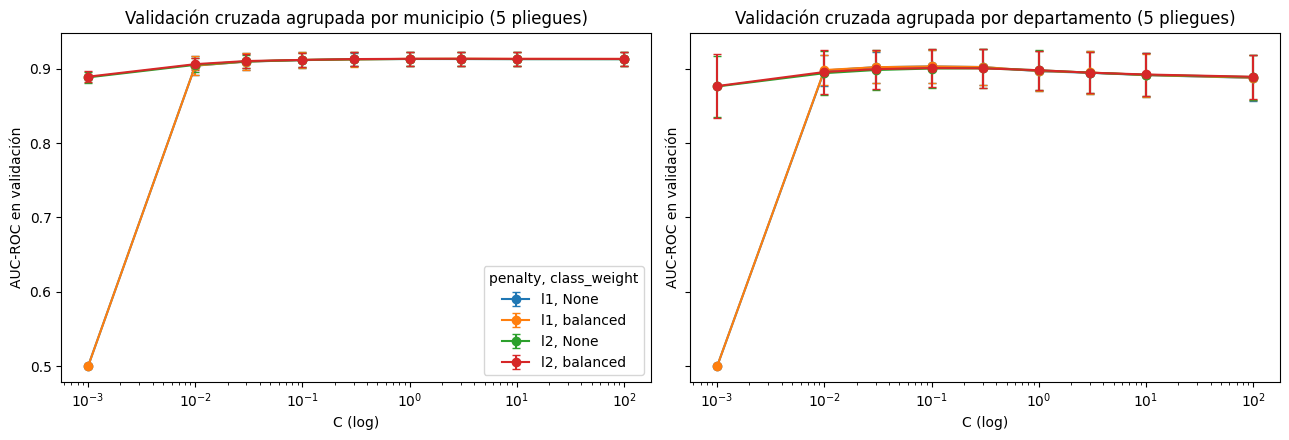

In [10]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5), sharey=True)
for eje, ag in zip(ax, AGRUPACIONES):
    t = tablas_cv[ag]
    for (pen, cw), d in t.assign(class_weight=t.class_weight.astype(str)).groupby(["penalty", "class_weight"]):
        d = d.sort_values("C")
        eje.errorbar(d.C.astype(float), d.AUC_val, yerr=d.AUC_val_sd, marker="o", capsize=3, label=f"{pen}, {cw}")
    eje.set_xscale("log"); eje.set_xlabel("C (log)"); eje.set_ylabel("AUC-ROC en validación")
    eje.set_title(f"Validación cruzada agrupada por {ag} (5 pliegues)")
ax[0].legend(title="penalty, class_weight")
plt.tight_layout(); plt.show()

## 9. Modelos finales

Cada `GridSearchCV` re-entrena su mejor combinación con todo el entrenamiento (2021–2024): un modelo final con los
hiperparámetros de la CV por municipio y otro con los de la CV por departamento.

In [11]:
finales = {ag: b.best_estimator_ for ag, b in busquedas.items()}
for ag, f in finales.items():
    coef_sk = pd.Series(f.named_steps["logit"].coef_.ravel(), index=f.named_steps["pre"].get_feature_names_out())
    print(f"[CV por {ag}] {mejores[ag]} | coeficientes llevados a cero por la penalizacion:",
          list(coef_sk[coef_sk == 0].index) or "ninguno")

[CV por municipio] {'C': 3, 'class_weight': 'balanced', 'penalty': 'l2'} | coeficientes llevados a cero por la penalizacion: ninguno
[CV por departamento] {'C': 0.1, 'class_weight': 'balanced', 'penalty': 'l1'} | coeficientes llevados a cero por la penalizacion: ['log_credito_ganaderia', 'log_credito_palma', 'region_Eje cafetero', 'region_Llano', 'region_Pacífico', 'ruralidad_Rural disperso']


## 10. Comparación de modelos: AUC

Los modelos se comparan sobre los mismos 639 municipios de 2025 con el **AUC-ROC**: la probabilidad de que un
municipio que deforestó reciba una probabilidad mayor que uno que no deforestó (0,5 = azar, 1 = perfecto).

- **Logística por actividad — CV por municipio / por departamento:** los dos modelos de este notebook.
- **Logística de totales (9 variables):** re-entrenada con la misma variable objetivo y el mismo entrenamiento
  (L2, C = 1, sin pesos).
- **Random Forest por actividad — CV por municipio / por departamento:** los modelos guardados de
  `random_forest_2.ipynb`.
- **Gradient boosting (equipo):** el modelo guardado de `modelos y clusters/gradient_boosting.ipynb`, con sus
  propias 15 variables (del mismo año que predice), cuyos hiperparámetros se eligieron agrupando por departamento.
- **Persistencia:** asigna la probabilidad observada en el entrenamiento según si el municipio deforestó o no el
  año anterior.

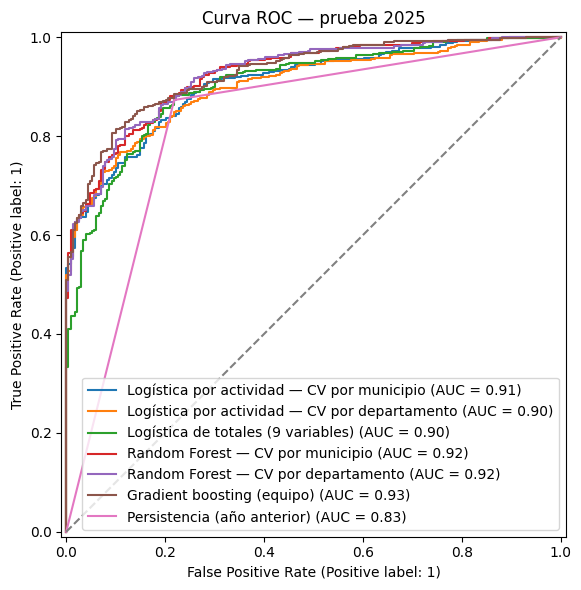

,AUC-ROC
Logística por actividad — CV por municipio,0.9062
Logística por actividad — CV por departamento,0.9030
Logística de totales (9 variables),0.9026
Random Forest — CV por municipio,0.9246
Random Forest — CV por departamento,0.9245
Gradient boosting (equipo),0.9278
Persistencia (año anterior),0.8274


In [12]:
import joblib
from sklearn.metrics import RocCurveDisplay, roc_auc_score


def metricas(y, prob):
    return {"AUC-ROC": roc_auc_score(y, prob)}


ETIQUETA = {ag: f"Logística por actividad — CV por {ag}" for ag in AGRUPACIONES}
prob_test = {ag: f.predict_proba(X_test)[:, 1] for ag, f in finales.items()}
logit_ant = Pipeline([("pre", preprocesador(NUMERICAS_ANT)),
                      ("logit", LogisticRegression(C=1, penalty="l2", solver="liblinear", max_iter=5000))])
logit_ant.fit(train[NUMERICAS_ANT + CATEGORICAS], y_train)

modelos = {ETIQUETA[ag]: prob_test[ag] for ag in AGRUPACIONES}
modelos["Logística de totales (9 variables)"] = logit_ant.predict_proba(test[NUMERICAS_ANT + CATEGORICAS])[:, 1]
ruta_rf = Path("datos/analisis/modelo_random_forest_rural_departamento/modelo_random_forest.joblib")
if ruta_rf.exists():
    rf_guardados = joblib.load(ruta_rf)
    for ag, rf_g in rf_guardados.items():
        modelos[f"Random Forest — CV por {ag}"] = rf_g["modelo"].predict_proba(test[rf_g["variables"]])[:, 1]
# --- Gradient boosting del equipo, sobre los mismos municipios de 2025
import lightgbm  # noqa: F401  (necesario para cargar el modelo)
test_gb = ns_gb["muestra"].query("anio == 2025").assign(cod_dane=lambda d: d.cod_dane.astype(str)).set_index("cod_dane")
gb = joblib.load("modelos y clusters/resultados/gradient_boosting_clasificador.joblib")
modelos["Gradient boosting (equipo)"] = gb.predict_proba(test_gb.loc[test.cod_dane.astype(str), ns_gb["EXPLICATIVAS"]])[:, 1]
p["deforesta_l1"] = p.groupby("cod_dane", observed=True).deforesta.shift(1)
tasa_cond = train.assign(l1=p.loc[train.index, "deforesta_l1"]).groupby("l1").deforesta.mean()
modelos["Persistencia (año anterior)"] = p.loc[test.index, "deforesta_l1"].map(tasa_cond).fillna(y_train.mean()).values
tabla_eval = pd.DataFrame({k: metricas(y_test, v) for k, v in modelos.items()}).T

fig, ax = plt.subplots(figsize=(7, 6))
for nombre, prob in modelos.items():
    RocCurveDisplay.from_predictions(y_test, prob, ax=ax, name=nombre)
ax.plot([0, 1], [0, 1], "--", color="grey"); ax.set_title("Curva ROC — prueba 2025")
plt.tight_layout(); plt.show()
tabla_eval.round(4)

## 11. Comparación de modelos: matriz de confusión

Cada modelo clasifica los municipios de 2025 con el **mismo umbral de 0,5**: si la probabilidad predicha es
0,5 o más, se clasifica como "deforesta". Usar el mismo umbral permite comparar los modelos directamente, y
0,5 es también el umbral que usa el gradient boosting (`predict`).

- **Verdaderos positivos:** municipios que deforestaron y el modelo los detectó.
- **Falsos negativos:** municipios que deforestaron y el modelo no los detectó.
- **Falsos positivos:** municipios que no deforestaron pero el modelo los marcó.
- **Verdaderos negativos:** municipios que no deforestaron y el modelo acertó.

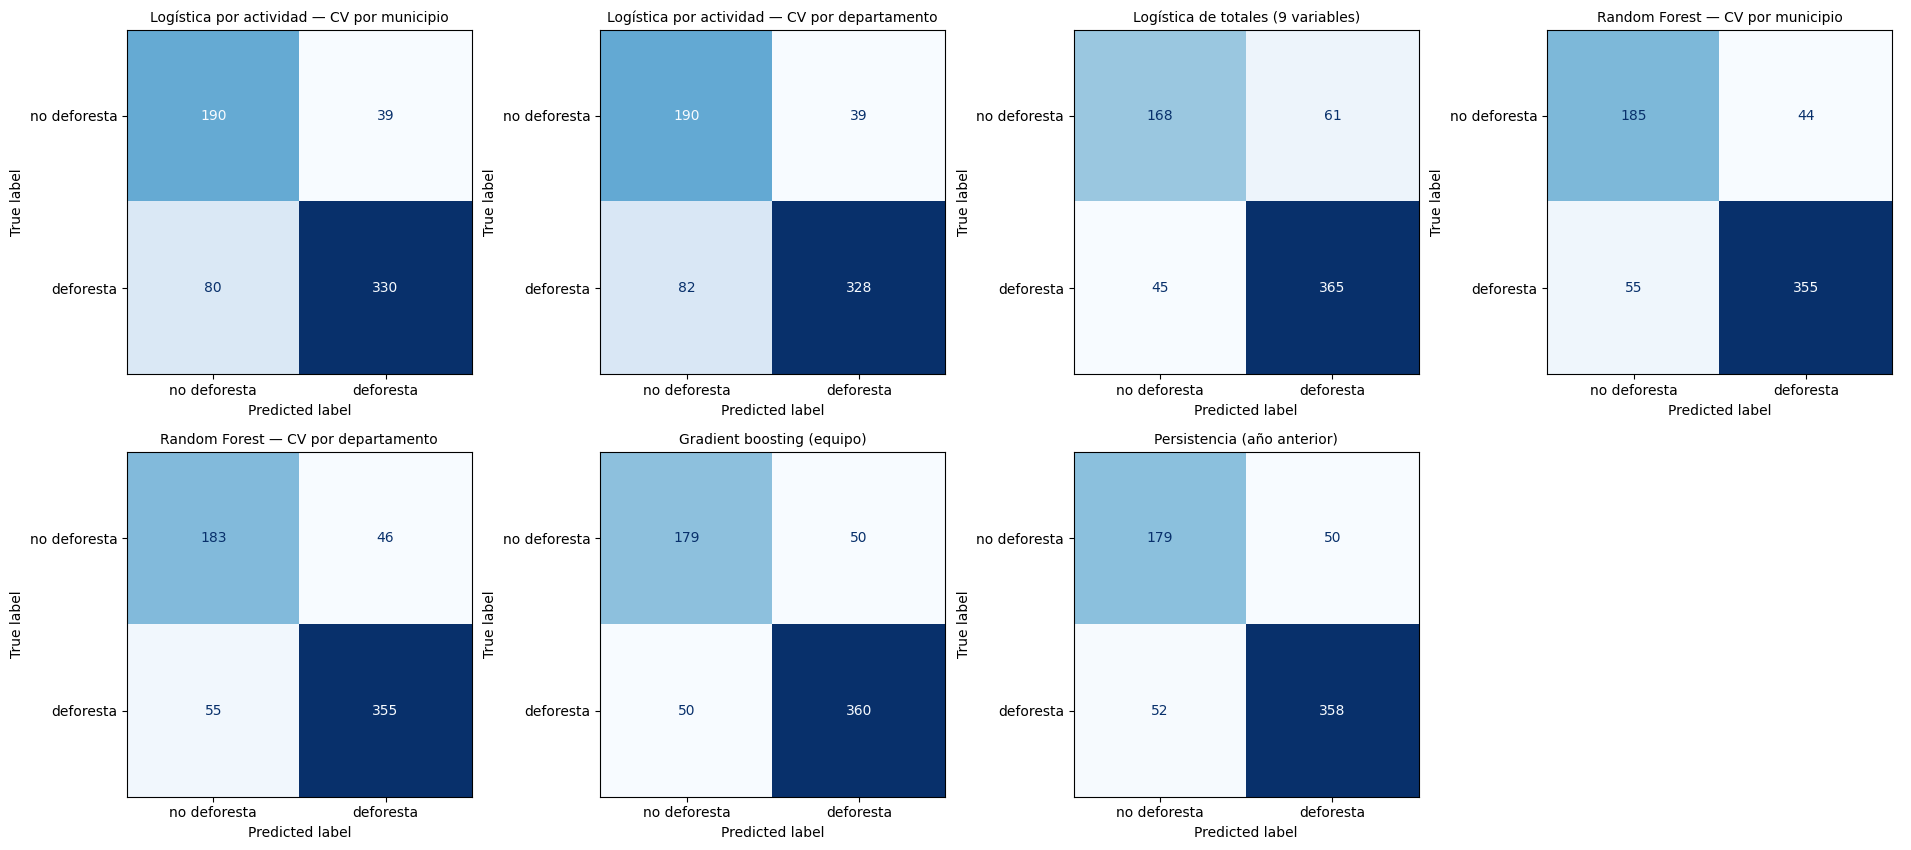

,verdaderos negativos,falsos positivos,falsos negativos,verdaderos positivos,aciertos
modelo,,,,,
Logística por actividad — CV por municipio,190,39,80,330,520
Logística por actividad — CV por departamento,190,39,82,328,518
Logística de totales (9 variables),168,61,45,365,533
Random Forest — CV por municipio,185,44,55,355,540
Random Forest — CV por departamento,183,46,55,355,538
Gradient boosting (equipo),179,50,50,360,539
Persistencia (año anterior),179,50,52,358,537


In [13]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

UMBRAL = 0.5
NCOL = 4
nfil = int(np.ceil(len(modelos) / NCOL))
fig, ax = plt.subplots(nfil, NCOL, figsize=(4.8 * NCOL, 4.3 * nfil))
filas = []
for eje, (nombre, prob) in zip(ax.ravel(), modelos.items()):
    pred = (prob >= UMBRAL).astype(int)
    cm = confusion_matrix(y_test, pred)
    ConfusionMatrixDisplay(cm, display_labels=["no deforesta", "deforesta"]).plot(ax=eje, cmap="Blues", colorbar=False)
    eje.set_title(nombre, fontsize=10)
    tn, fp, fn, tp = cm.ravel()
    filas.append({"modelo": nombre, "verdaderos negativos": tn, "falsos positivos": fp,
                  "falsos negativos": fn, "verdaderos positivos": tp, "aciertos": tn + tp})
for eje in ax.ravel()[len(modelos):]:
    eje.axis("off")
plt.tight_layout(); plt.show()
pred_test = {ag: (prob_test[ag] >= UMBRAL).astype(int) for ag in AGRUPACIONES}
matrices = pd.DataFrame(filas).set_index("modelo")
matrices

## 12. Evaluación dejando territorios completos fuera (2021–2025)

Los pasos 10 y 11 miden la generalización **en el tiempo**, pero los 639 municipios de la prueba son los mismos
que el modelo vio en entrenamiento. Aquí se mide la generalización **en el territorio**, igual que la sección 6
del gradient boosting: `GroupKFold` de 5 pliegues sobre **todo 2021–2025**, con los hiperparámetros ya elegidos
(sin volver a buscar ni a calcular el VIF). En cada pliegue se entrena con los grupos restantes y se predice el
grupo que quedó fuera.

Se cruzan las dos agrupaciones: los hiperparámetros elegidos con cada CV se evalúan dejando fuera municipios y
dejando fuera departamentos. Como referencia se muestran el Random Forest (de
`random_forest_2.ipynb`) y el gradient boosting (de `gradient_boosting_metricas.csv`).

In [14]:
from sklearn.base import clone
from sklearn.metrics import balanced_accuracy_score

m_todo = muestra.reset_index(drop=True)
X_todo, y_todo = m_todo[X_COLS], m_todo.deforesta
filas, prob_oof = [], {}
for ag_hp, f in finales.items():
    for ag_eval, col in AGRUPACIONES.items():
        prob = np.full(len(m_todo), np.nan)
        for i_dentro, i_fuera in GroupKFold(n_splits=5).split(X_todo, y_todo, groups=m_todo[col].astype(str)):
            mod = clone(f).fit(X_todo.iloc[i_dentro], y_todo.iloc[i_dentro])
            prob[i_fuera] = mod.predict_proba(X_todo.iloc[i_fuera])[:, 1]
        prob_oof[(ag_hp, ag_eval)] = prob
        pred = (prob >= UMBRAL).astype(int)
        filas.append({"modelo": ETIQUETA[ag_hp], "evaluacion": f"{ag_eval}s fuera", "AUC-ROC": roc_auc_score(y_todo, prob),
                      "exactitud balanceada": balanced_accuracy_score(y_todo, pred), "aciertos %": 100 * (pred == y_todo).mean()})
eval_territorio = pd.DataFrame(filas)

# Referencias: Random Forest (mismo procedimiento) y gradient boosting (departamentos fuera)
ruta_rf_terr = Path("datos/analisis/modelo_random_forest_rural_departamento/evaluacion_territorios_fuera.csv")
referencias = [pd.read_csv(ruta_rf_terr).assign(modelo=lambda d: d.modelo.str.replace("RF por actividad", "Random Forest"))] if ruta_rf_terr.exists() else []
evaluacion_completa = pd.concat([eval_territorio] + referencias, ignore_index=True).drop_duplicates(["modelo", "evaluacion"])
print(f"Filas evaluadas: {len(m_todo):,} (2021-2025) | departamentos: {m_todo.nombre_departamento.astype(str).nunique()}")
evaluacion_completa.pivot(index="modelo", columns="evaluacion", values=["AUC-ROC", "exactitud balanceada"]).round(4)

Filas evaluadas: 3,195 (2021-2025) | departamentos: 31


AUC-ROC                  exactitud balanceada                 
evaluacion                                    departamentos fuera municipios fuera  departamentos fuera municipios fuera
modelo                                                                                                                  
Gradient boosting (equipo)                                 0.9088              NaN               0.8132              NaN
Logística por actividad — CV por departamento              0.9059           0.9100               0.8257           0.8247
Logística por actividad — CV por municipio                 0.8999           0.9117               0.8147           0.8226
Random Forest — CV por departamento                        0.9070           0.9107               0.8136           0.8139
Random Forest — CV por municipio                           0.9064           0.9122               0.8126           0.8159

## 13. Interpretación

Para la inferencia, el modelo se re-estima con `statsmodels` sin regularización ni pesos, para obtener errores
estándar, intervalos y p-valores. Los coeficientes de esa estimación no dependen de la agrupación, pero los
**errores estándar sí**. Se calculan de dos formas:

- **Agrupados por municipio** (*cluster-robust*, versión original): un mismo municipio aparece en varios años del
  entrenamiento, así que sus observaciones no son independientes.
- **Agrupados por departamento:** además permiten que los municipios de un mismo departamento tengan errores
  correlacionados. Con 31 grupos, son más conservadores: los intervalos se ensanchan y los p-valores suben.

Las columnas `coef_sklearn` muestran los coeficientes de los dos modelos penalizados, para verificar que coinciden
en signo y magnitud.

Las numéricas están estandarizadas. Así, el **odds ratio (OR)** se lee como: "un aumento de una desviación
estándar en la variable multiplica las odds de deforestar por OR", manteniendo lo demás constante. Las
categóricas se comparan contra la categoría base (región Caribe, ruralidad "Ciudades y aglomeraciones").

In [15]:
# El preprocesador (imputacion + estandarizacion + dummies) es el mismo en los dos modelos finales
pre_f = finales["municipio"].named_steps["pre"]
X_sm = sm.add_constant(pd.DataFrame(pre_f.transform(X_train), columns=pre_f.get_feature_names_out(), index=X_train.index))
logit_sm = {}
for ag in AGRUPACIONES:
    logit_sm[ag] = sm.Logit(y_train, X_sm).fit(disp=0, cov_type="cluster", cov_kwds={"groups": pd.factorize(grupos_train[ag])[0]})
print(logit_sm["municipio"].summary2().tables[0].to_string(header=False, index=False))

coefs = pd.DataFrame({"coef": logit_sm["municipio"].params, "OR": np.exp(logit_sm["municipio"].params)})
for ag, corto in [("municipio", "mun"), ("departamento", "dep")]:
    ic = logit_sm[ag].conf_int()
    coefs[f"OR_IC95_inf_{corto}"] = np.exp(ic[0])
    coefs[f"OR_IC95_sup_{corto}"] = np.exp(ic[1])
    coefs[f"p_valor_{corto}"] = logit_sm[ag].pvalues
    coefs[f"signif_{corto}"] = pd.cut(coefs[f"p_valor_{corto}"], [0, 0.01, 0.05, 0.1, 1], labels=["***", "**", "*", ""])
for ag, corto in [("municipio", "mun"), ("departamento", "dep")]:
    lg = finales[ag].named_steps["logit"]
    coefs[f"coef_sklearn_{corto}"] = np.r_[lg.intercept_, lg.coef_.ravel()]
coefs.drop("const").sort_values("OR", ascending=False).round(3)

             Model:            Logit           Method:       MLE
Dependent Variable:        deforesta Pseudo R-squared:     0.474
              Date: 2026-11-15 17:33              AIC: 1809.6089
  No. Observations:             2556              BIC: 1914.8405
          Df Model:               17   Log-Likelihood:   -886.80
      Df Residuals:             2538          LL-Null:   -1685.0
         Converged:           1.0000      LLR p-value:    0.0000
    No. Iterations:           8.0000            Scale:    1.0000


,coef,OR,OR_IC95_inf_mun,OR_IC95_sup_mun,p_valor_mun,signif_mun,OR_IC95_inf_dep,OR_IC95_sup_dep,p_valor_dep,signif_dep,coef_sklearn_mun,coef_sklearn_dep
log_bosque_inicial,2.684,14.643,10.778,19.893,0.000,***,8.907,24.071,0.000,***,2.707,2.340
log_cosechada_cacao,0.375,1.455,1.105,1.915,0.008,***,1.105,1.915,0.008,***,0.392,0.423
log_credito_cacao,0.323,1.381,1.088,1.753,0.008,***,1.058,1.803,0.018,**,0.321,0.221
log_cosechada_otros,0.316,1.372,1.060,1.775,0.016,**,1.041,1.808,0.025,**,0.316,0.198
log_credito_arroz,0.148,1.160,0.929,1.448,0.190,,0.934,1.441,0.180,,0.146,0.006
log_cosechada_arroz,0.096,1.101,0.861,1.408,0.443,,0.871,1.392,0.421,,0.133,0.170
log_credito_palma,0.010,1.010,0.764,1.335,0.946,,0.771,1.323,0.944,,-0.019,0.000
ruralidad_Rural disperso,-0.009,0.992,0.719,1.367,0.959,,0.779,1.263,0.945,,-0.016,0.000
log_cosechada_palma,-0.036,0.964,0.721,1.290,0.807,,0.706,1.317,0.820,,-0.011,0.124
log_credito_ganaderia,-0.098,0.907,0.667,1.234,0.534,,0.541,1.519,0.710,,-0.074,0.000


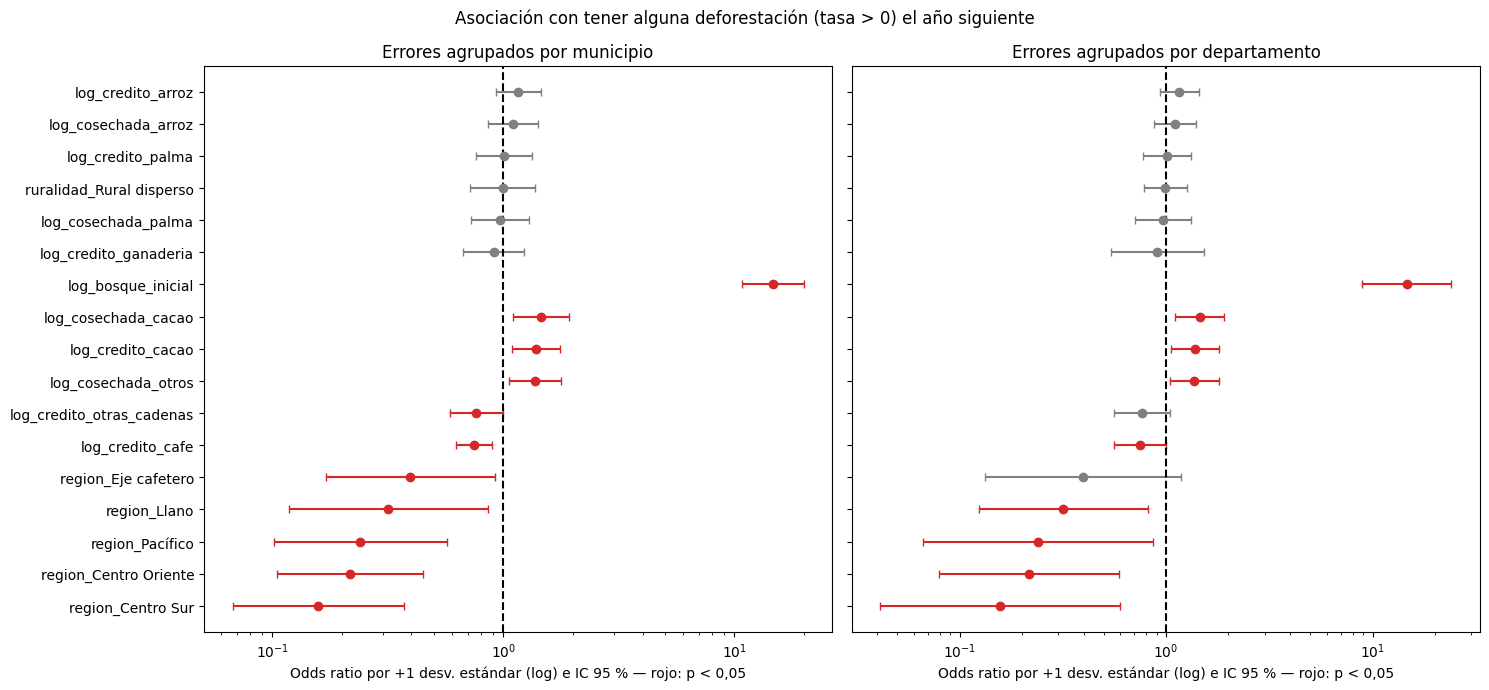

In [16]:
d = coefs.drop("const").sort_values("OR")
fig, ax = plt.subplots(1, 2, figsize=(15, 7), sharey=True)
for eje, (ag, corto) in zip(ax, [("municipio", "mun"), ("departamento", "dep")]):
    for signif, color in [(True, "C3"), (False, "grey")]:
        s = d[(d[f"p_valor_{corto}"] < 0.05) == signif]
        eje.errorbar(s.OR, s.index, xerr=[s.OR - s[f"OR_IC95_inf_{corto}"], s[f"OR_IC95_sup_{corto}"] - s.OR],
                     fmt="o", capsize=3, color=color)
    eje.axvline(1, ls="--", color="black"); eje.set_xscale("log")
    eje.set_xlabel("Odds ratio por +1 desv. estándar (log) e IC 95 % — rojo: p < 0,05")
    eje.set_title(f"Errores agrupados por {ag}")
fig.suptitle("Asociación con tener alguna deforestación (tasa > 0) el año siguiente")
plt.tight_layout(); plt.show()

In [17]:
# Efectos marginales promedio: cambio en la probabilidad (en puntos) por +1 desviacion estandar
print(f"Pseudo-R2 de McFadden: {logit_sm['municipio'].prsquared:.3f}")
efm = {}
for ag in AGRUPACIONES:
    e = logit_sm[ag].get_margeff(at="overall").summary_frame()
    e = e.loc[NUMERICAS, ["dy/dx", "Pr(>|z|)", "Conf. Int. Low", "Cont. Int. Hi."]]
    e.insert(1, "puntos_porcentuales", e["dy/dx"] * 100)
    efm[ag] = e
efm = pd.concat({f"errores por {ag}": e for ag, e in efm.items()}, axis=1)
efm.sort_values(("errores por municipio", "dy/dx")).round(4)

Pseudo-R2 de McFadden: 0.474


errores por municipio                                                            errores por departamento                                                           
                                          dy/dx puntos_porcentuales Pr(>|z|) Conf. Int. Low Cont. Int. Hi.                    dy/dx puntos_porcentuales Pr(>|z|) Conf. Int. Low Cont. Int. Hi.
log_credito_cafe                        -0.0322             -3.2153   0.0016        -0.0521        -0.0122                  -0.0322             -3.2153   0.0567        -0.0652         0.0009
log_credito_otras_cadenas               -0.0298             -2.9800   0.0496        -0.0596        -0.0000                  -0.0298             -2.9800   0.0935        -0.0646         0.0050
log_credito_ganaderia                   -0.0108             -1.0842   0.5337        -0.0450         0.0233                  -0.0108             -1.0842   0.7100        -0.0680         0.0463
log_cosechada_palma                     -0.0040             -0.4021   0.8071        -0.0363         0.0283                  -0.0040             -0.4021   0.8199        -0.0386         0.0306
log_credito_palma                        0.0011              0.1066   0.9462        -0.0299         0.0320                   0.0011              0.1066   0.9444        -0.0289         0.0311
log_cosechada_arroz                      0.0107              1.0677   0.4430        -0.0166         0.0380                   0.0107              1.0677   0.4143        -0.0150         0.0363
log_credito_arroz                        0.0165              1.6454   0.1881        -0.0080         0.0410                   0.0165              1.6454   0.1744        -0.0073         0.0402
log_cosechada_otros                      0.0351              3.5058   0.0162         0.0065         0.0636                   0.0351              3.5058   0.0286         0.0037         0.0664
log_credito_cacao                        0.0358              3.5818   0.0081         0.0093         0.0623                   0.0358              3.5818   0.0210         0.0054         0.0662
log_cosechada_cacao                      0.0416              4.1585   0.0067         0.0115         0.0717                   0.0416              4.1585   0.0068         0.0115         0.0717
log_bosque_inicial                       0.2978             29.7820   0.0000         0.2766         0.3191                   0.2978             29.7820   0.0000         0.2711         0.3245

### Pesos del modelo final

Los **pesos** son los coeficientes β del modelo final de scikit-learn, con los hiperparámetros elegidos en el paso 8 (uno por agrupación). El modelo calcula
la probabilidad de deforestar como:

$$\text{logit}(p) = \beta_0 + \sum_j \beta_j \, x_j \qquad\Rightarrow\qquad p = \frac{1}{1 + e^{-\text{logit}(p)}}$$

- **Signo del peso:** positivo, la variable sube la probabilidad. Negativo, la baja.
- **`peso` en las numéricas:** cambio del logit por **+1 desviación estándar** de la variable (están
  estandarizadas). `OR_por_sd = e^β` es el factor que multiplica las odds.
- **`OR_duplicar`:** como las numéricas están en log(1 + x), un peso por desviación estándar se traduce en el
  efecto de **duplicar** el crédito, el área o el ganado: `OR_duplicar = e^(β · ln 2 / sd_log)`.
- **`peso` en las dummies:** efecto de pertenecer a esa categoría frente a la base (región Caribe, ruralidad
  "Ciudades y aglomeraciones").
- **`peso_estandarizado` = |β| × desviación estándar de la columna:** pone numéricas y dummies en la misma
  escala (cuánto mueve el logit una variación típica de la columna). De ahí sale la **participación (%)** de cada
  variable y de cada bloque en la influencia total del modelo.
- **`p_valor_cluster`:** p-valor con los errores agrupados de la misma agrupación del modelo.

In [18]:
sd_log = pd.Series(pre_f.named_transformers_["num"].named_steps["esc"].scale_, index=NUMERICAS)
cols_f = pre_f.get_feature_names_out()
Xf_train = X_sm.drop(columns="const")

pesos = {}
for ag, f in finales.items():
    logit_f = f.named_steps["logit"]
    t = pd.DataFrame({"peso": logit_f.coef_.ravel()}, index=cols_f)
    t["OR_por_sd"] = np.exp(t.peso)
    t["OR_duplicar"] = np.exp(t.peso.reindex(NUMERICAS) / sd_log * np.log(2))
    t["peso_estandarizado"] = t.peso.abs() * Xf_train.std()
    t["participacion_%"] = 100 * t.peso_estandarizado / t.peso_estandarizado.sum()
    t["p_valor_cluster"] = logit_sm[ag].pvalues.reindex(cols_f)
    t["direccion"] = np.where(t.peso > 0, "sube", "baja")
    t = t.sort_values("peso_estandarizado", ascending=False)
    t.insert(0, "rango", range(1, len(t) + 1))
    pesos[ag] = t
    print(f"[CV por {ag}] intercepto (beta_0): {logit_f.intercept_[0]:.3f}")
pd.concat({f"CV por {ag}": t for ag, t in pesos.items()}, axis=1).sort_values(("CV por departamento", "rango")).round(3)

[CV por municipio] intercepto (beta_0): 1.753
[CV por departamento] intercepto (beta_0): 0.773


CV por municipio                                                                                           CV por departamento                               \
                                     rango   peso OR_por_sd OR_duplicar peso_estandarizado participacion_% p_valor_cluster direccion               rango   peso OR_por_sd OR_duplicar   
log_bosque_inicial                       1  2.707    14.980       2.231              2.707          39.731           0.000      sube                   1  2.340    10.382       2.001   
log_cosechada_cacao                      5  0.392     1.481       1.107              0.392           5.760           0.008      sube                   2  0.423     1.527       1.116   
log_credito_cafe                         6 -0.350     0.704       0.924              0.350           5.143           0.001      baja                   3 -0.348     0.706       0.924   
log_credito_otras_cadenas               10 -0.276     0.758       0.897              0.276           4.058           0.049      baja                   4 -0.226     0.798       0.915   
log_credito_cacao                        7  0.321     1.379       1.094              0.321           4.718           0.008      sube                   5  0.221     1.247       1.064   
log_cosechada_otros                      8  0.316     1.371       1.140              0.316           4.634           0.016      sube                   6  0.198     1.219       1.086   
log_cosechada_arroz                     13  0.133     1.142       1.032              0.133           1.946           0.443      sube                   7  0.170     1.185       1.041   
region_Centro Oriente                    2 -1.255     0.285         NaN              0.601           8.822           0.000      baja                   8 -0.317     0.728         NaN   
log_cosechada_palma                     16 -0.011     0.990       0.997              0.011           0.155           0.807      baja                   9  0.124     1.133       1.034   
region_Centro Sur                        3 -1.628     0.196         NaN              0.569           8.349           0.000      baja                  10 -0.321     0.726         NaN   
log_credito_arroz                       12  0.146     1.157       1.041              0.146           2.144           0.190      sube                  11  0.006     1.006       1.002   
region_Llano                             9 -0.898     0.408         NaN              0.277           4.063           0.024      baja                  12  0.000     1.000         NaN   
region_Pacífico                          4 -1.112     0.329         NaN              0.407           5.977           0.001      baja                  13  0.000     1.000         NaN   
log_credito_ganaderia                   14 -0.074     0.929       0.978              0.074           1.086           0.534      baja                  14  0.000     1.000       1.000   
region_Eje cafetero                     11 -0.656     0.519         NaN              0.206           3.027           0.031      baja                  15  0.000     1.000         NaN   
log_credito_palma                       15 -0.019     0.982       0.994              0.019           0.273           0.946      baja                  16  0.000     1.000       1.000   
ruralidad_Rural disperso                17 -0.016     0.984         NaN              0.008           0.116           0.959      baja                  17  0.000     1.000         NaN   

                                                                                        
                          peso_estandarizado participacion_% p_valor_cluster direccion  
log_bosque_inicial                     2.341          54.163           0.000      sube  
log_cosechada_cacao                    0.424           9.802           0.008      sube  
log_credito_cafe                       0.348           8.062           0.048      baja  
log_credito_otras_cadenas              0.226           5.228     

In [19]:
def bloque(c):
    if c.startswith("log_credito"):
        return "Crédito por cadena"
    if c.startswith("log_cosechada"):
        return "Cosecha por cultivo"
    if c.startswith("region_"):
        return "Región"
    if c.startswith("ruralidad_"):
        return "Ruralidad"
    return {"log_bovinos": "Bovinos", "log_bosque_inicial": "Bosque inicial"}[c]


def actividad(c):
    for act, nombre in {"ganaderia": "Ganadería", "cafe": "Café", "arroz": "Arroz", "cacao": "Cacao", "palma": "Palma"}.items():
        if c.endswith("_" + act):
            return nombre
    if c == "log_bovinos":
        return "Ganadería"
    if c in ("log_credito_otras_cadenas", "log_cosechada_otros"):
        return "Otras actividades"
    return None


part_bloque, part_act = {}, {}
for ag, t in pesos.items():
    part_bloque[ag] = t.groupby(t.index.map(bloque))["participacion_%"].sum().sort_values(ascending=False)
    ta = t[t.index.map(actividad).notna()]
    pa = pd.DataFrame({"participacion_%": ta.groupby(ta.index.map(actividad))["participacion_%"].sum(),
                       "suma_pesos": ta.groupby(ta.index.map(actividad))["peso"].sum()}).sort_values("participacion_%", ascending=False)
    pa["direccion_neta"] = np.where(pa.suma_pesos > 0, "sube", "baja")
    part_act[ag] = pa
display(pd.DataFrame({f"CV por {ag}": s for ag, s in part_bloque.items()}).round(1))
pd.concat({f"CV por {ag}": t for ag, t in part_act.items()}, axis=1).round(3)

,CV por municipio,CV por departamento
Bosque inicial,39.7,54.2
Cosecha por cultivo,12.5,21.2
Crédito por cadena,17.4,18.5
Región,30.2,6.1
Ruralidad,0.1,0.0


CV por municipio                           CV por departamento                          
                   participacion_% suma_pesos direccion_neta     participacion_% suma_pesos direccion_neta
Cacao                       10.478      0.714           sube              14.908      0.644           sube
Otras actividades            8.692      0.039           sube               9.812     -0.028           baja
Café                         5.143     -0.350           baja               8.062     -0.348           baja
Arroz                        4.090      0.279           sube               4.067      0.176           sube
Ganadería                    1.086     -0.074           baja               0.000      0.000           baja
Palma                        0.428     -0.029           baja               2.881      0.124           sube

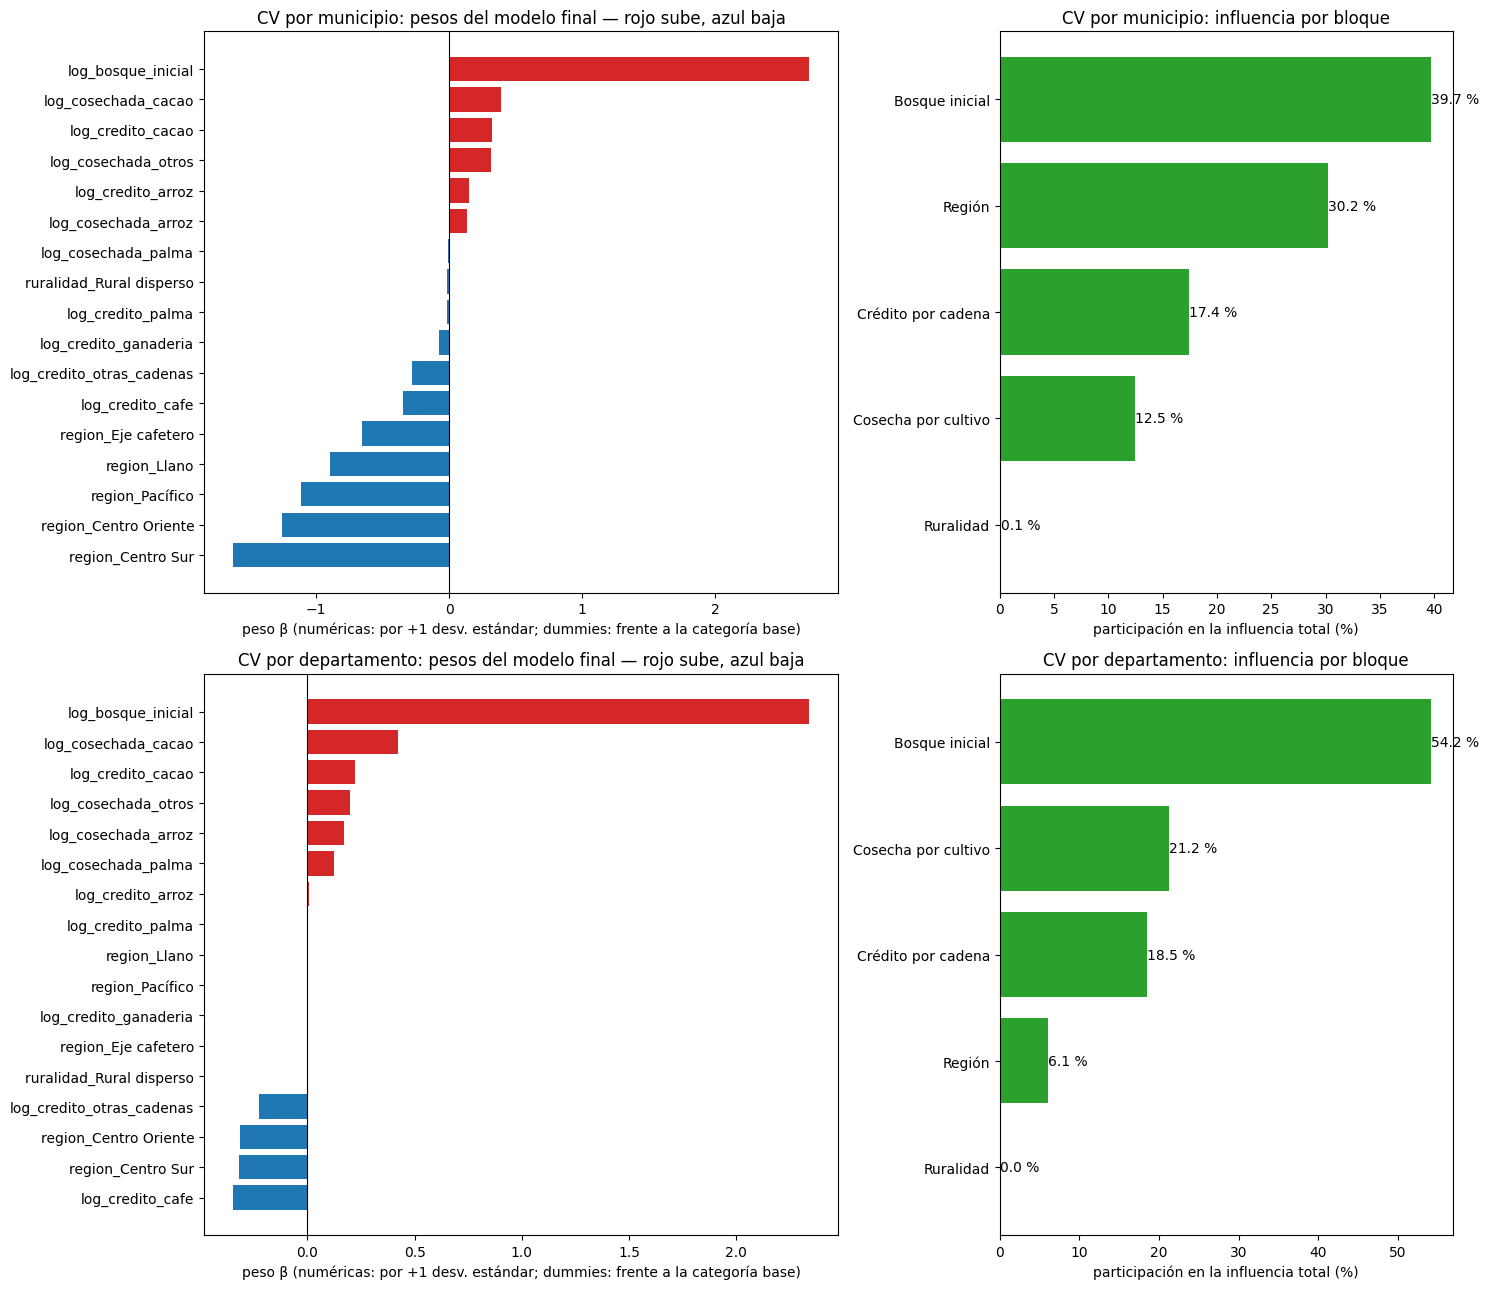

In [20]:
fig, ax = plt.subplots(2, 2, figsize=(15, 13), gridspec_kw={"width_ratios": [1.4, 1]})
for fila, ag in enumerate(AGRUPACIONES):
    d = pesos[ag].sort_values("peso")
    ax[fila, 0].barh(d.index, d.peso, color=np.where(d.peso > 0, "C3", "C0"))
    ax[fila, 0].axvline(0, color="black", lw=0.8)
    ax[fila, 0].set_xlabel("peso β (numéricas: por +1 desv. estándar; dummies: frente a la categoría base)")
    ax[fila, 0].set_title(f"CV por {ag}: pesos del modelo final — rojo sube, azul baja")
    b = part_bloque[ag].sort_values()
    ax[fila, 1].barh(b.index, b.values, color="C2")
    ax[fila, 1].bar_label(ax[fila, 1].containers[0], fmt="%.1f %%")
    ax[fila, 1].set_xlabel("participación en la influencia total (%)")
    ax[fila, 1].set_title(f"CV por {ag}: influencia por bloque")
plt.tight_layout(); plt.show()

### Pruebas conjuntas por bloque y por actividad

Una prueba de Wald conjunta responde si **todas** las variables de un bloque son a la vez cero. Se calcula con la
covarianza agrupada por municipio y con la agrupada por departamento. Es la versión inferencial de la permutación
por bloques del Random Forest, y evita concluir que una actividad "no importa" solo porque sus variables,
correlacionadas entre sí, salen individualmente no significativas.

In [21]:
def wald(modelo_sm, cols):
    cols = [c for c in cols if c in X_sm.columns]
    if not cols:
        return {"n_variables": 0, "chi2": np.nan, "p_valor": np.nan}
    R = np.zeros((len(cols), len(X_sm.columns)))
    for i, c in enumerate(cols):
        R[i, X_sm.columns.get_loc(c)] = 1
    t = modelo_sm.wald_test(R, scalar=True)
    return {"n_variables": len(cols), "chi2": float(t.statistic), "p_valor": float(t.pvalue)}


dummies = lambda var: [c for c in X_sm.columns if c.startswith(var + "_")]
bloques = {"Crédito (cadenas)": CREDITO, "Cosecha (cultivos)": COSECHA, "Bovinos": ["log_bovinos"],
           "Bosque inicial": ["log_bosque_inicial"], "Región": dummies("region"), "Ruralidad": dummies("ruralidad")}
actividades = {"Ganadería (crédito + bovinos)": ["log_credito_ganaderia", "log_bovinos"],
               "Café (crédito + área)": ["log_credito_cafe", "log_cosechada_cafe"],
               "Arroz (crédito + área)": ["log_credito_arroz", "log_cosechada_arroz"],
               "Cacao (crédito + área)": ["log_credito_cacao", "log_cosechada_cacao"],
               "Palma (crédito + área)": ["log_credito_palma", "log_cosechada_palma"],
               "Otras actividades (crédito + área)": ["log_credito_otras_cadenas", "log_cosechada_otros"]}
pruebas = {}
for ag in AGRUPACIONES:
    t = pd.concat({"bloque": pd.DataFrame({k: wald(logit_sm[ag], v) for k, v in bloques.items()}).T,
                   "actividad": pd.DataFrame({k: wald(logit_sm[ag], v) for k, v in actividades.items()}).T})
    t["signif"] = pd.cut(t.p_valor.astype(float), [-1, 0.01, 0.05, 0.1, 1], labels=["***", "**", "*", ""])
    pruebas[ag] = t
pruebas = pd.concat({f"errores por {ag}": t for ag, t in pruebas.items()}, axis=1)
pruebas.round(4)

errores por municipio                          errores por departamento                         
                                                       n_variables      chi2 p_valor signif              n_variables      chi2 p_valor signif
bloque    Crédito (cadenas)                                    6.0   24.3724  0.0004    ***                      6.0   18.8708  0.0044    ***
          Cosecha (cultivos)                                   4.0   16.7015  0.0022    ***                      4.0   33.3349  0.0000    ***
          Bovinos                                              0.0       NaN     NaN    NaN                      0.0       NaN     NaN    NaN
          Bosque inicial                                       1.0  294.7161  0.0000    ***                      1.0  111.9969  0.0000    ***
          Región                                               5.0   27.2810  0.0001    ***                      5.0   13.0168  0.0232     **
          Ruralidad                                            1.0    0.0027  0.9586                             1.0    0.0048  0.9450       
actividad Ganadería (crédito + bovinos)                        1.0    0.3871  0.5338                             1.0    0.1378  0.7105       
          Café (crédito + área)                                1.0   10.1045  0.0015    ***                      1.0    3.8964  0.0484     **
          Arroz (crédito + área)                               2.0    5.0180  0.0814      *                      2.0    2.7591  0.2517       
          Cacao (crédito + área)                               2.0   53.2461  0.0000    ***                      2.0   64.1442  0.0000    ***
          Palma (crédito + área)                               2.0    0.0688  0.9662                             2.0    0.0546  0.9731       
          Otras actividades (crédito + área)                   2.0    6.5375  0.0381     **                      2.0    5.6390  0.0596      *

## 14. Comparación de especificaciones

Con los hiperparámetros elegidos por cada agrupación. Como el modelo C necesita la deforestación del año anterior, que no existe
para 2021, los tres se entrenan con 2022–2024 y se evalúan en 2025. Se comparan con el AUC-ROC.

| Modelo | Variables |
|---|---|
| A. Estructural | `log_bosque_inicial`, región, ruralidad |
| B. Principal | A + crédito por cadena, cosecha por cultivo y bovinos (después del VIF) |
| C. Con persistencia | B + deforestación del año anterior (`log_def_l1`) |

In [22]:
especificaciones = {"A. Estructural": ["log_bosque_inicial"], "B. Principal": NUMERICAS,
                    "C. Con persistencia": NUMERICAS + ["log_def_l1"]}
train_c, test_c = train[train.anio >= 2022], test[test.anio >= 2022]
filas = []
for ag in AGRUPACIONES:
    for nombre, num in especificaciones.items():
        m = Pipeline([("pre", preprocesador(num)),
                      ("logit", LogisticRegression(solver="liblinear", max_iter=5000, random_state=SEMILLA, **mejores[ag]))])
        m.fit(train_c[num + CATEGORICAS], train_c.deforesta)
        filas.append({"modelo": nombre, "agrupacion_cv": f"CV por {ag}", "n_variables": len(num) + len(CATEGORICAS),
                      **metricas(test_c.deforesta, m.predict_proba(test_c[num + CATEGORICAS])[:, 1])})
comparacion = pd.DataFrame(filas).pivot(index=["modelo", "n_variables"], columns="agrupacion_cv", values="AUC-ROC")
comparacion.round(4)

,agrupacion_cv,CV por departamento,CV por municipio
modelo,n_variables,,
A. Estructural,3,0.8888,0.9007
B. Principal,13,0.9006,0.9060
C. Con persistencia,14,0.9147,0.9194


## 15. Guardado

En `datos/analisis/modelo_logistico_rural_departamento/`, una carpeta ignorada por git. El `joblib` guarda un
diccionario con los dos modelos (`"municipio"` y `"departamento"`). La carpeta del notebook original
(`modelo_logistico_rural/`) no se toca.

In [23]:
SALIDA = Path("datos/analisis/modelo_logistico_rural_departamento")
SALIDA.mkdir(parents=True, exist_ok=True)
joblib.dump({ag: {"modelo": finales[ag], "umbral": UMBRAL, "variables": X_COLS, "eliminadas_vif": eliminadas,
                  "regla_objetivo": REGLA_OBJETIVO, "hiperparametros": mejores[ag], "agrupacion_cv": ag}
             for ag in AGRUPACIONES}, SALIDA / "modelo_logistico.joblib")
test[["cod_dane", "nombre_departamento", "nombre_municipio", "anio", "def_ideam_ha", "deforesta"]].assign(
    **{f"prob_logit_cv_{ag}": prob_test[ag] for ag in AGRUPACIONES},
    **{f"pred_logit_cv_{ag}": pred_test[ag] for ag in AGRUPACIONES}).to_csv(SALIDA / "predicciones_prueba.csv", index=False)
coefs.to_csv(SALIDA / "coeficientes.csv")
pd.concat(pesos, names=["agrupacion_cv"]).to_csv(SALIDA / "pesos_modelo_final.csv")
pd.concat({ag: pd.concat({"bloque": part_bloque[ag].to_frame(), "actividad": part_act[ag]}) for ag in AGRUPACIONES},
          names=["agrupacion_cv"]).to_csv(SALIDA / "pesos_por_bloque.csv")
efm.to_csv(SALIDA / "efectos_marginales.csv")
pruebas.to_csv(SALIDA / "pruebas_wald_bloques.csv")
pd.concat(historial, axis=1).to_csv(SALIDA / "vif_iterativo.csv")
pd.concat(tablas_cv, names=["agrupacion_cv"]).to_csv(SALIDA / "grid_search_resultados.csv")
resumen_cv.to_csv(SALIDA / "resumen_hiperparametros.csv")
eval_territorio.to_csv(SALIDA / "evaluacion_territorios_fuera.csv", index=False)
pd.concat({"evaluacion": tabla_eval, "especificaciones": comparacion.reset_index("n_variables", drop=True)}).to_csv(SALIDA / "metricas.csv")
print(sorted(f.name for f in SALIDA.iterdir()))

['coeficientes.csv', 'efectos_marginales.csv', 'evaluacion_territorios_fuera.csv', 'grid_search_resultados.csv', 'metricas.csv', 'modelo_logistico.joblib', 'pesos_modelo_final.csv', 'pesos_por_bloque.csv', 'predicciones_prueba.csv', 'pruebas_wald_bloques.csv', 'resumen_hiperparametros.csv', 'vif_iterativo.csv']


## 16. Conclusiones

### 16.1 Configuración e hiperparámetros

- **Muestra, partición y variables:** las mismas de `regresion_logistica.ipynb`. Son 639 municipios rurales con
  bosque, con entrenamiento 2021–2024 y prueba 2025. El VIF iterativo elimina `log_cosechada_cafe` y `log_bovinos`,
  y el modelo queda con **13 variables**. El VIF no depende de la agrupación.

| | CV por municipio | CV por departamento |
|---|---|---|
| `penalty` · `C` · `class_weight` | L2 · 3 · `balanced` | **L1 · 0,1** · `balanced` |
| AUC de validación (desv. entre pliegues) | 0,913 (0,009) | **0,903 (0,022)** |
| AUC de la misma combinación con la otra CV | 0,895 con CV por departamento | 0,912 con CV por municipio |
| Coeficientes llevados a cero | ninguno | crédito ganadero, crédito a palma, regiones Eje cafetero, Llano y Pacífico, ruralidad |

- **Con departamentos fuera, la búsqueda elige un modelo mucho más regularizado** (C 30 veces menor y L1). Aquí la
  elección sí importa: medida con la CV por departamento, la combinación elegida por municipio pierde 0,008 de AUC
  (0,895 frente a 0,903). Con la CV por municipio, la elegida por departamento pierde solo 0,002.
- **La penalización elimina casi toda la región.** Tres de las cinco dummies quedan en cero, y Centro Oriente y
  Centro Sur se encogen de −1,3 y −1,6 a −0,3. Lo que la región aprende en unos departamentos no se transfiere bien
  a otros.

### 16.2 Comparación de modelos en 2025 (639 municipios rurales)

| Modelo | AUC-ROC | Falsos positivos | Falsos negativos | Aciertos |
|---|---|---|---|---|
| Gradient boosting (equipo) | **0,928** | 50 | **50** | 539 (84,4 %) |
| Random Forest — CV por municipio | 0,925 | 44 | 55 | **540 (84,5 %)** |
| Random Forest — CV por departamento | 0,925 | 46 | 55 | 538 (84,2 %) |
| Logística por actividad — CV por municipio | 0,906 | **39** | 80 | 520 (81,4 %) |
| Logística por actividad — CV por departamento | 0,903 | **39** | 82 | 518 (81,1 %) |
| Logística de totales (9 variables) | 0,903 | 61 | 45 | 533 (83,4 %) |
| Persistencia (año anterior) | 0,827 | 50 | 52 | 537 (84,0 %) |

- En 2025, **la logística por departamento pierde 0,003 de AUC.** Es lo esperable: los municipios de 2025 son los
  mismos del entrenamiento, y ahí la región sí ayuda.
- Las dos logísticas siguen siendo conservadoras con el umbral de 0,5 por el peso `balanced`: pocos falsos
  positivos (39) y muchos falsos negativos (80–82).
- La versión por municipio reproduce exactamente los resultados de `regresion_logistica.ipynb`.

### 16.3 Generalización a territorios nuevos (2021–2025, 3.195 filas)

| Modelo | AUC, municipios fuera | AUC, departamentos fuera | Exactitud balanceada, departamentos fuera |
|---|---|---|---|
| Logística — CV por municipio | **0,912** | 0,900 | 0,815 |
| **Logística — CV por departamento** | 0,910 | **0,906** | **0,826** |
| Random Forest — CV por municipio | **0,912** | 0,906 | 0,813 |
| Random Forest — CV por departamento | 0,911 | 0,907 | 0,814 |
| Gradient boosting (equipo) | — | **0,909** | 0,813 |

- **Este es el hallazgo principal de la versión por departamento.** Con departamentos completos fuera, la logística
  regularizada sube de 0,900 a 0,906 de AUC y **queda a la altura del Random Forest (0,907) y a 0,003 del gradient
  boosting**. Su exactitud balanceada (0,826) es la mayor de todos los modelos, gracias al peso `balanced`.
- La ventaja de los árboles en 2025 (unas 0,02 de AUC) viene sobre todo de conocer a los municipios. En territorios
  nuevos, los tres modelos quedan casi empatados.

### 16.4 Inferencia con errores agrupados por departamento

Los coeficientes de `statsmodels` son los mismos con las dos agrupaciones. Con 31 grupos, los intervalos se
ensanchan:

| Variable | OR por +1 desv. est. | p, agrupado por municipio | p, agrupado por departamento |
|---|---|---|---|
| Bosque inicial | 14,6 | < 0,001 | < 0,001 |
| Área de cacao | 1,46 | 0,008 | 0,008 |
| Crédito al cacao | 1,38 | 0,008 | 0,018 |
| Área de otros cultivos | 1,37 | 0,016 | 0,025 |
| Crédito al café | 0,75 | 0,001 | **0,048** |
| Crédito a otras cadenas | 0,76 | 0,049 | **0,091** (deja de ser significativo al 5 %) |
| Región Eje cafetero (frente a Caribe) | 0,40 | 0,031 | **0,095** (deja de ser significativo al 5 %) |
| Demás regiones (frente a Caribe) | 0,16 a 0,32 | ≤ 0,03 | ≤ 0,03 |
| Crédito y área de arroz, ganadería, palma, ruralidad | ≈ 1 | ≥ 0,19 | ≥ 0,18 |

**Pruebas de Wald por actividad** (municipio → departamento): **cacao** < 0,001 → < 0,001 · **café** 0,002 → 0,048 ·
otras actividades 0,038 → 0,060 · arroz 0,081 → 0,25 · ganadería 0,53 → 0,71 · palma 0,97 → 0,97. Los bloques de
crédito (p = 0,004), cosecha (p < 0,001), bosque (p < 0,001) y región (p = 0,023) siguen siendo significativos en
conjunto.

**Influencia por bloque en el modelo final** (municipio → departamento): bosque 39,7 % → 54,2 % · cosecha
12,5 % → 21,2 % · crédito 17,4 % → 18,5 % · región 30,2 % → 6,1 % · ruralidad 0,1 % → 0 %. En el modelo por
departamento, las actividades productivas pesan el **39,7 %** de la influencia, frente al 29,9 %, porque la región
casi desaparece.

**Especificaciones** (AUC en 2025, entrenando con 2022–2024), CV por municipio → CV por departamento: estructural
0,901 → 0,889 · principal 0,906 → 0,901 · con persistencia 0,919 → 0,915.

### 16.5 En resumen

- Con errores agrupados por departamento, **los hallazgos centrales se mantienen.** El bosque domina, el cacao
  (área y crédito) sube la probabilidad de deforestar y el crédito cafetero la baja, aunque este último queda justo
  en el límite (p = 0,048). La ganadería, el arroz y la palma siguen sin efecto significativo.
- Lo que se debilita es la región y el crédito a otras cadenas.
- Para predecir en departamentos que el modelo no conoce, **la logística elegida por departamento generaliza tan
  bien como el Random Forest**, y además se puede interpretar coeficiente por coeficiente.